# mmg_toolbox example
## Load NeXus files as XAS Spectra and calculate XMCD
This short notebook describes an example of spectroscopy data analysis.

### *Notebook Notes*
This notebook will run with any modern version of python and requires *mmg_toolbox*, which can be installed easily using:
```bash
python -m pip install mmg_toolbox
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mmg_toolbox import Experiment, module_info

print(module_info())


Python version 3.14.5 (main, Jun  2 2026, 22:25:17) [Clang 22.1.3 ]
 at: /scratch/grp66007/python/mmg_toolbox/.venv/bin/python
 mmg_toolbox version 0.7.1 (17/09/2026): /scratch/grp66007/python/mmg_toolbox/mmg_toolbox/__init__.py
     numpy version: 2.5.3
      h5py version: 3.16.0
matplotlib version: 3.11.2
    hdfmap version: 1.4.0 (2026/08/28)
   tkinter version: 9.0



In [2]:
# Create experiment object looking at a particular folder
exp = Experiment('/dls/science/groups/das/ExampleData/hdfmap_tests/i10', instrument='i10-1')

print(exp)

print(exp.all_scans_str())


Instrument: i10-1
/dls/science/groups/das/ExampleData/hdfmap_tests/i10
    Files: 12
    Scans: 207-921636
i10/i10-1-207.nxs : 2024-04-10 18:20:22.094000     : cvscan energye 695 740 0.1 mcse16 0.28 mcse17 0.28 mcse18 0.28 
i10/i10-1-26851.nxs : 2025-03-26 10:59:09.009000     : cvscan energy 925 940 0.1 mcsh16 0.2 mcsh17 0.2 mcsh18 0.2 mcsh19 0.2 
i10/i10-1-28428.nxs : 2025-03-30 21:07:49.143000     : scan ips_field 7 -7.1 0.2 pol ('pc', 'nc') energy (701, 707.15, 708.33, 709.05, 773, 778.29) checkbeam macj216 macj217 macj218 5
i10/i10-1-37436.nxs : 2025-06-23 13:23:58.236000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
i10/i10-1-37437.nxs : 2025-06-23 13:26:27.759000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
i10/i10-1-37438.nxs : 2025-06-23 13:30:18.476000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
i10/i10-1-37439.nxs : 2025-06-23 13:32:47.677000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
i10/i1

In [3]:
# Load scan files as Spectra objects, automatically loading and normalising the data, finding the edge
spectra = exp.load_xas(37436, 37437, 37438, 37439, dls_loader=True, mode='tey')

for spectrum in spectra:
    m = spectrum.metadata
    print(spectrum.label())
    #print(f"Spectrum: {spectrum.name} T={m.temp:.1f} K, B={m.mag_field:+3.1f} T, pol='{m.pol}'")



37436 FeL3, L2 T=10K 'pc' B=+1T
37437 FeL3, L2 T=10K 'pc' B=-1T
37438 FeL3, L2 T=10K 'nc' B=-1T
37439 FeL3, L2 T=10.1K 'nc' B=+1T


Text(0, 0.5, 'Signal / monitor')

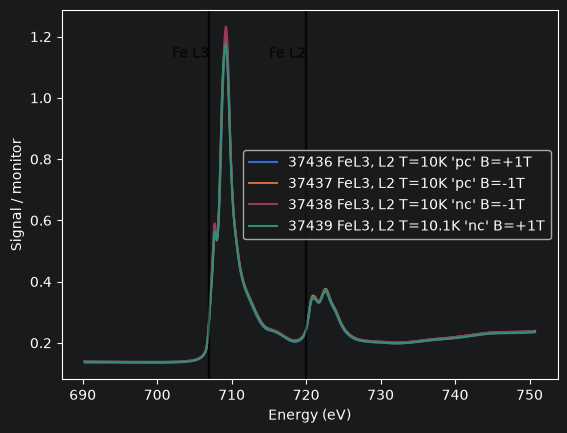

In [4]:
# Plot the spectra
fig, ax = plt.subplots()
for spectrum in spectra:
    spectrum.plot('tey', axes=ax, label=spectrum.label())
ax.legend()
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('Signal / monitor')

Text(0, 0.5, 'Signal / monitor')

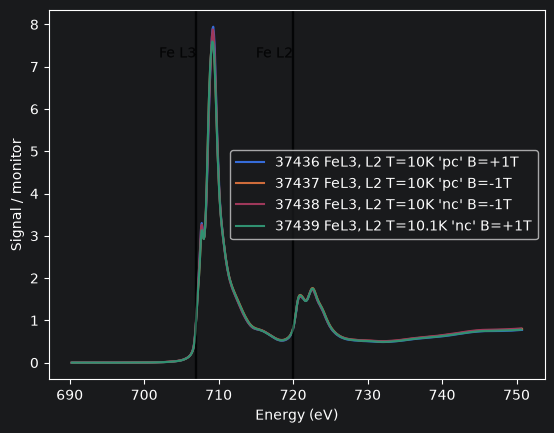

In [5]:
# Process each spectra by applying a series of actions
# in this case, divide by the pre-edge region, then remove a linearly fitted background
spectra = [
    spectrum.divide_by_preedge(ev_from_start=5).remove_background('linear')
    for spectrum in spectra
]

# Plot the processed spectra
fig, ax = plt.subplots()
for spectrum in spectra:
    spectrum.plot('tey', axes=ax, label=spectrum.label())
ax.legend()
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('Signal / monitor')


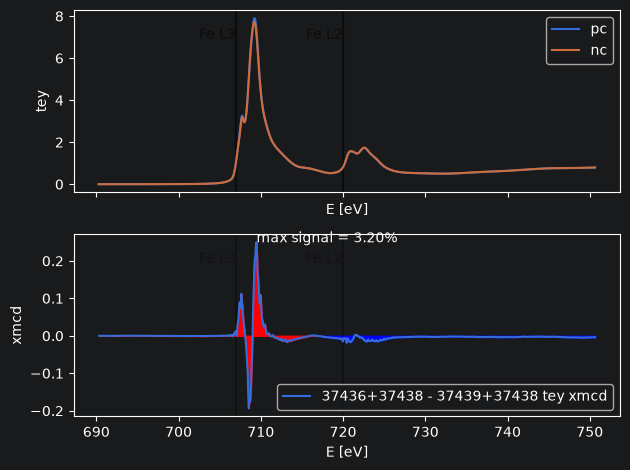

In [6]:
# separate the spectra into individual Spectra objects and calculate the subtractions
up_right, down_right, down_left, up_left = spectra
xmcd_field1 = up_right - down_right
xmcd_field2 = up_left - down_left
xmcd_pol1 = up_left - up_right
xmcd_pol2 = down_left - down_right

av_pol1 = up_right + down_left
av_pol2 = up_left + down_left
xmcd_av = av_pol1 - av_pol2

# Create Sum Rules plot
xmcd_av.create_sum_rules_figure(split_energy=717)
plt.tight_layout()
plt.show()




In [7]:
# Determine the Sum Rules

print(xmcd_av.sum_rules_report(mode='tey', split_energy=717, n_holes=None))


=== Sum Rules === 
tey signal = 3.20%
Split energy between Fe L3, L2 edges: 717 eV
Fe n_holes = 4, energy split = 717 eV
L = 0.007 μB
S = -0.044 μB


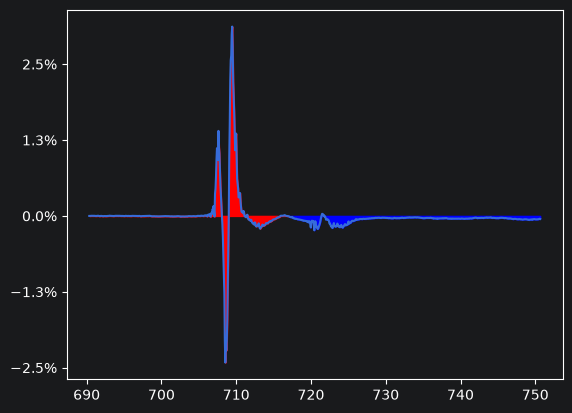

In [8]:
# Plot XMCD as ratio to XAS peak
s = xmcd_av.spectra['tey']
s.plot_sum_rules_ratio(split_energy=717)

In [9]:
# Write output NeXus file
xmcd_av.write_nexus('xmcd.nxs')

Created xmcd.nxs


In [10]:
# Write data as CSV for VirtualBeamline App
spectra = exp.load_xas(37436, 37437, 37438, 37439, dls_loader=True, mode='tey')
for spectrum in spectra:
    spectrum.write_csv(f"{spectrum.label()}.csv", 'tey')

print('\nOpening file:')
with open("37436 FeL3, L2 T=10K 'pc' B=+1T.csv") as f:
    print(f.read())

Saved 37436 FeL3, L2 T=10K 'pc' B=+1T.csv
Saved 37437 FeL3, L2 T=10K 'pc' B=-1T.csv
Saved 37438 FeL3, L2 T=10K 'nc' B=-1T.csv
Saved 37439 FeL3, L2 T=10.1K 'nc' B=+1T.csv

Opening file:
# 37436 raw
# energy, tey
6.903443000000000893e+02, 1.360528726338575134e-01
6.905007000000000517e+02, 1.360358056265984772e-01
6.906035000000000537e+02, 1.360550479828780412e-01
6.907003000000000839e+02, 1.360113853834774011e-01
6.908006000000000313e+02, 1.359833490819010726e-01
6.909010000000000673e+02, 1.359819286334167099e-01
6.909918000000000120e+02, 1.359827725217639671e-01
6.910917000000000598e+02, 1.359583346085962985e-01
6.911861000000000104e+02, 1.359557752964845045e-01
6.912780000000000200e+02, 1.359363333579668709e-01
6.913654000000000224e+02, 1.359676280899706768e-01
6.914565000000000055e+02, 1.360118645665840120e-01
6.915518000000000711e+02, 1.359814202696301988e-01
6.916499999999999773e+02, 1.358996799487103835e-01
6.917475000000000591e+02, 1.358664422397266314e-01
6.918413000000000466e+02

In [19]:
# Write data as CSV for VirtualBeamline App
spectra = exp.load_xas(37436, 37437, 37438, 37439, dls_loader=True, mode='tey')
for spectrum in spectra:
    # spectrum.write_csv(f"{spectrum.label()}.csv", 'tey')
    m = spectrum.metadata
    tey = m.raw_signals['tey']
    en = m.energy
    mon = m.monitor

    filename = f"VBA_{m.scan_no}_{m.pol}_{m.mag_field:.0f}T.csv"
    np.savetxt(filename, np.array([en, tey, mon]).T, delimiter=',', header='energy, TEY, monitor')
    print(f"Saved {filename}")

Saved VBA_37436_pc_1T.csv
Saved VBA_37437_pc_-1T.csv
Saved VBA_37438_nc_-1T.csv
Saved VBA_37439_nc_1T.csv


Text(0, 0.5, 'Signal / monitor')

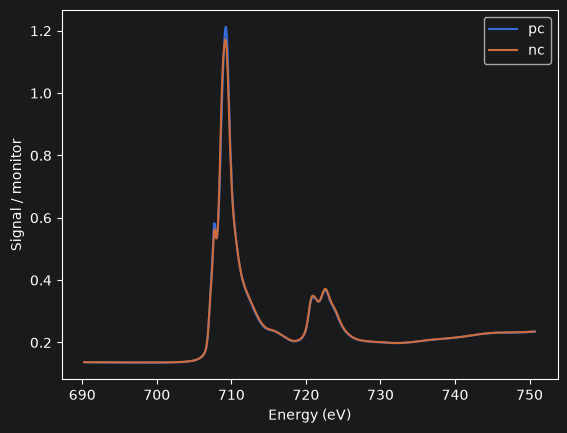

In [22]:
# Load CSV files and plot them
c1 = np.loadtxt('VBA_37436_pc_1T.csv', delimiter=',')
c2 = np.loadtxt('VBA_37439_nc_1T.csv', delimiter=',')

fig, ax = plt.subplots()

ax.plot(c1[:, 0], c1[:, 1] / c1[:, 2], label='pc')
ax.plot(c2[:, 0], c2[:, 1] / c2[:, 2], label='nc')
ax.legend()
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('Signal / monitor')

Text(0, 0.5, 'Signal / monitor')

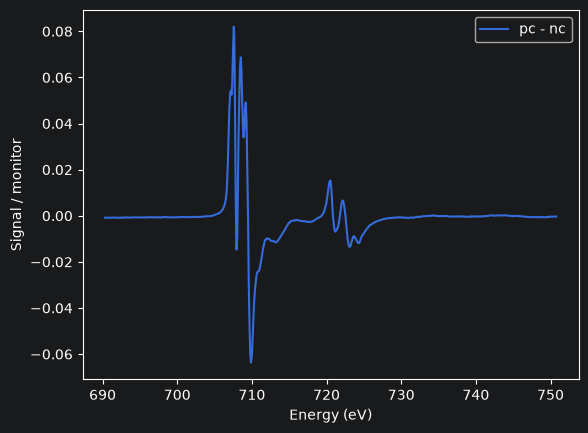

In [23]:
# plot RAW xmcd (no processing)
fig, ax = plt.subplots()
ax.plot(c1[:, 0], (c1[:, 1] / c1[:, 2]) - (c2[:, 1] / c2[:, 2]), label='pc - nc')
ax.legend()
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('Signal / monitor')